# 04 – Deep dives: robustness checks and additional angles

Uses `data/processed/bcsc_clean.parquet` and the XGBoost model saved by `02_modeling.ipynb` (`xgb_menohrt.json`).
Everything is weighted by `count` (number of mammograms), so "share" means share of mammograms, not of women.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
import xgboost as xgb
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from prepare import MENO_HRT_FEATURES, TARGET, WEIGHT, add_meno_hrt, safe_name

PROCESSED = ROOT / "data/processed"
FIG_DIR = ROOT / "output"
PINK, NEUTRAL, INK_2 = "#c2185b", "#9a9893", "#52514e"
BINOMIAL = sm.families.Binomial()

clean = add_meno_hrt(pd.read_parquet(PROCESSED / "bcsc_clean.parquet"))
known = clean[clean[TARGET].notna()].copy()
booster = xgb.Booster()
booster.load_model(PROCESSED / "xgb_menohrt.json")
FEATURES = booster.feature_names
test = pd.read_parquet(PROCESSED / "model_menohrt_test.parquet")
p_test = booster.predict(xgb.DMatrix(test[FEATURES]))
y_test, w_test = test[TARGET], test[WEIGHT]


def lab(col, df=known):
    """Label column with missing values as an explicit 'Unknown' category (as in the model)."""
    s = df[f"{col}_label"]
    return s.cat.add_categories("Unknown").fillna("Unknown") if s.isna().any() else s


def encode(profiles: pd.DataFrame) -> pd.DataFrame:
    """One-hot encode label columns (one per model variable) into the booster's feature layout."""
    cols = {}
    for var in MENO_HRT_FEATURES:
        names = (var + "_" + profiles[var].astype(str)).map(safe_name)
        missing = set(names) - set(FEATURES)
        assert not missing, missing
        for name in names.unique():
            cols[name] = (names == name).astype("float32").to_numpy()
    return pd.DataFrame(cols, index=profiles.index).reindex(columns=FEATURES, fill_value=0.0)


def predict(profiles: pd.DataFrame) -> np.ndarray:
    return booster.predict(xgb.DMatrix(encode(profiles)))


print(f"{known['count'].sum():,} mammograms with known density; test set: {w_test.sum():,}")

6,028,759 mammograms with known density; test set: 1,223,806


## 1. Adjusted vs. raw

For each factor: the **raw** share of mammograms with high density per group, and the **adjusted** share from a weighted logistic
regression controlling for age, BMI and menopause/HRT (unknowns as their own category). The adjusted share is a
standardized prediction: everyone in the data is assigned that group, everything else stays as observed, and the
predictions are averaged. Raw and adjusted are therefore on the same scale and directly comparable.

- **HRT** is analyzed among naturally postmenopausal women only, adjusting for age and BMI (meno_hrt contains HRT
  itself, and surgical menopause is never recorded with HRT use).
- "What happens" compares the raw and adjusted odds ratios. An OR between 0.95 and 1.05 counts as "no effect"; otherwise
  the % is the share of the raw log-odds effect that remains after adjustment.

In [2]:
base = pd.DataFrame({
    "dense": known[TARGET].astype(int), "w": known["count"],
    "age": lab("age_group_5_years").astype(str), "bmi": lab("bmi_group").astype(str),
    "meno_hrt": lab("meno_hrt").astype(str),
    "race": known["race_eth_label"].astype(object), "hrt": known["current_hrt_label"].astype(object),
    "famhx": known["first_degree_hx_label"].astype(object), "natural_post": known["menopaus"] == 2,
})


def describe_change(raw_logor, adj_logor, none=np.log(1.05)):
    raw_none, adj_none = abs(raw_logor) < none, abs(adj_logor) < none
    if raw_none and adj_none:
        return "no effect either way"
    if raw_none:
        return "appears after adjustment"
    if adj_none:
        return "disappears"
    if np.sign(raw_logor) != np.sign(adj_logor):
        return "reverses"
    pct = 100 * adj_logor / raw_logor
    return f"shrinks ({pct:.0f}% left)" if pct < 100 else f"grows ({pct:.0f}%)"


def raw_vs_adjusted(exposure, reference, covariates, data):
    data = data[data[exposure].notna()]
    agg = data.groupby([exposure, *covariates, "dense"])["w"].sum().reset_index()
    term = f"C({exposure}, Treatment('{reference}'))"
    raw = smf.glm(f"dense ~ {term}", agg, family=BINOMIAL, freq_weights=agg["w"]).fit()
    adj = smf.glm(f"dense ~ {term} + " + " + ".join(f"C({c})" for c in covariates), agg,
                  family=BINOMIAL, freq_weights=agg["w"]).fit()
    rows = []
    for level in [reference] + sorted(set(agg[exposure]) - {reference}):
        g = agg[agg[exposure] == level]
        row = {"factor": exposure, "group": level, "mammograms": g["w"].sum(),
               "raw_share": np.average(g["dense"], weights=g["w"]),
               "adjusted_share": np.average(adj.predict(agg.assign(**{exposure: level})), weights=agg["w"])}
        if level != reference:
            name = f"{term}[T.{level}]"
            for tag, fit in (("raw", raw), ("adj", adj)):
                lo, hi = fit.conf_int().loc[name]
                row |= {f"{tag}_OR": np.exp(fit.params[name]), f"{tag}_CI": f"{np.exp(lo):.2f}–{np.exp(hi):.2f}"}
            row["what_happens"] = describe_change(raw.params[name], adj.params[name])
        rows.append(row)
    return pd.DataFrame(rows)


comparison = pd.concat([
    raw_vs_adjusted("race", "Non-Hispanic white", ["age", "bmi", "meno_hrt"], base),
    raw_vs_adjusted("hrt", "No", ["age", "bmi"], base[base["natural_post"]]),
    raw_vs_adjusted("famhx", "No", ["age", "bmi", "meno_hrt"], base),
], ignore_index=True)
comparison.to_csv(PROCESSED / "raw_vs_adjusted.csv", index=False)
comparison.style.format({"mammograms": "{:,.0f}", "raw_share": "{:.1%}", "adjusted_share": "{:.1%}",
                         "raw_OR": "{:.2f}", "adj_OR": "{:.2f}"}, na_rep="ref")

,factor,group,mammograms,raw_share,adjusted_share,raw_OR,raw_CI,adj_OR,adj_CI,what_happens
0,race,Non-Hispanic white,"4,048,367",46.5%,46.5%,ref,ref,ref,ref,ref
1,race,Asian/Pacific Islander,"506,696",65.1%,57.9%,2.15,2.14–2.16,1.69,1.68–1.70,shrinks (69% left)
2,race,Hispanic,"325,945",45.7%,44.5%,0.97,0.96–0.97,0.91,0.90–0.92,appears after adjustment
3,race,Native American,"18,001",45.4%,46.2%,0.96,0.93–0.99,0.99,0.95–1.02,no effect either way
4,race,Non-Hispanic black,"701,418",40.9%,46.8%,0.80,0.79–0.80,1.01,1.01–1.02,disappears
5,race,Other/mixed,"94,941",48.1%,46.2%,1.07,1.05–1.08,0.98,0.97–1.00,disappears
6,hrt,No,"2,693,698",37.3%,37.9%,ref,ref,ref,ref,ref
7,hrt,Yes,"306,062",49.1%,43.4%,1.63,1.61–1.64,1.28,1.27–1.29,shrinks (51% left)
8,famhx,No,"4,771,469",47.4%,47.0%,ref,ref,ref,ref,ref
9,famhx,Yes,"1,004,198",47.1%,49.0%,0.99,0.99–0.99,1.10,1.09–1.10,appears after adjustment


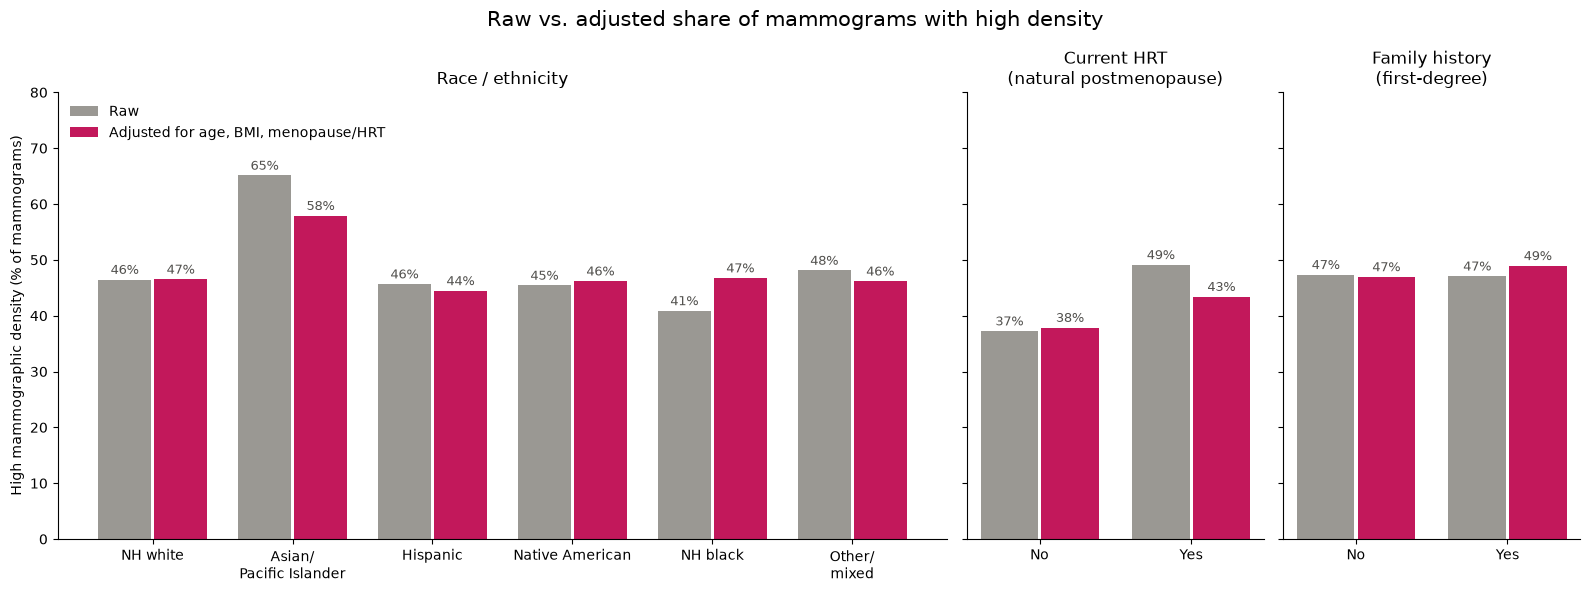

In [3]:
titles = {"race": "Race / ethnicity", "hrt": "Current HRT\n(natural postmenopause)", "famhx": "Family history\n(first-degree)"}
fig, axes = plt.subplots(1, 3, figsize=(16, 6), gridspec_kw={"width_ratios": [6, 2, 2]}, sharey=True)
for ax, (factor, g) in zip(axes, comparison.groupby("factor", sort=False)):
    x = np.arange(len(g))
    ax.bar(x - 0.2, g["raw_share"] * 100, width=0.38, color=NEUTRAL, label="Raw")
    ax.bar(x + 0.2, g["adjusted_share"] * 100, width=0.38, color=PINK, label="Adjusted for age, BMI, menopause/HRT")
    for xi, (r, a) in enumerate(zip(g["raw_share"], g["adjusted_share"])):
        ax.text(xi - 0.2, r * 100 + 1, f"{r:.0%}", ha="center", fontsize=9, color=INK_2)
        ax.text(xi + 0.2, a * 100 + 1, f"{a:.0%}", ha="center", fontsize=9, color=INK_2)
    ax.set_xticks(x, g["group"].str.replace("/", "/\n").str.replace("Non-Hispanic ", "NH "), fontsize=10)
    ax.set_title(titles[factor])
    ax.set_ylim(0, 80)
axes[0].set_ylabel("High mammographic density (% of mammograms)")
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Raw vs. adjusted share of mammograms with high density", fontsize=15)
sns.despine()
fig.tight_layout()
fig.savefig(FIG_DIR / "raw_vs_adjusted.png", dpi=150)

## 2. Model fairness

XGBoost on the held-out test set, per race/ethnicity and per age group: weighted ROC AUC, observed vs. mean predicted
share (calibration-in-the-large) and calibration slope (1 = ideal; <1 = predictions too extreme, >1 = too timid).

Within-group AUC is expected to be lower than overall for **age**: inside one age group the model loses age as a
discriminating factor. Lower AUC there does not mean the model is unfair.

In [4]:
def group_of(var):
    cols = [c for c in FEATURES if c.startswith(var + "_")]
    return test[cols].idxmax(axis=1).str[len(var) + 1:]


def calibration_slope(y, p, w):
    logit = np.log(p / (1 - p))
    return sm.GLM(y, sm.add_constant(logit), family=BINOMIAL, freq_weights=w).fit().params.iloc[1]


def group_metrics(var):
    groups = group_of(var)
    order = list(dict.fromkeys(c[len(var) + 1:] for c in FEATURES if c.startswith(var + "_")))
    rows = []
    for g in order:
        m = (groups == g).to_numpy()
        y, p, w = y_test[m], p_test[m], w_test[m]
        rows.append({"variable": var, "group": g, "mammograms": w.sum(),
                     "ROC_AUC": roc_auc_score(y, p, sample_weight=w),
                     "observed": np.average(y, weights=w), "predicted": np.average(p, weights=w),
                     "calib_slope": calibration_slope(y, p, w)})
    return pd.DataFrame(rows)


overall_auc = roc_auc_score(y_test, p_test, sample_weight=w_test)
fairness = pd.concat([group_metrics("race_eth"), group_metrics("age_group_5_years")], ignore_index=True)
fairness["obs_minus_pred_pp"] = (fairness["observed"] - fairness["predicted"]) * 100
fairness.to_csv(PROCESSED / "fairness_metrics.csv", index=False)
print(f"Overall test ROC AUC: {overall_auc:.3f}")
fairness.style.format({"mammograms": "{:,.0f}", "ROC_AUC": "{:.3f}", "observed": "{:.1%}", "predicted": "{:.1%}",
                       "calib_slope": "{:.2f}", "obs_minus_pred_pp": "{:+.1f}"})

Overall test ROC AUC: 0.720


,variable,group,mammograms,ROC_AUC,observed,predicted,calib_slope,obs_minus_pred_pp
0,race_eth,Non-Hispanic_white,"831,237",0.715,45.6%,47.0%,1.06,-1.4
1,race_eth,Non-Hispanic_black,"138,790",0.691,41.6%,41.1%,1.06,+0.5
2,race_eth,Asian/Pacific_Islander,"101,275",0.722,64.8%,64.3%,1.23,+0.5
3,race_eth,Native_American,"3,431",0.733,44.2%,44.6%,1.20,-0.4
4,race_eth,Hispanic,"64,887",0.731,45.4%,47.7%,1.16,-2.4
5,race_eth,Other/mixed,"19,489",0.734,47.4%,47.7%,1.10,-0.3
6,race_eth,Unknown,"64,697",0.704,46.1%,46.0%,1.21,+0.1
7,age_group_5_years,18-29,"1,708",0.729,67.6%,56.9%,1.38,+10.7
8,age_group_5_years,30-34,"7,710",0.759,71.2%,64.1%,1.57,+7.1
9,age_group_5_years,35-39,"28,346",0.688,72.3%,66.5%,1.13,+5.8


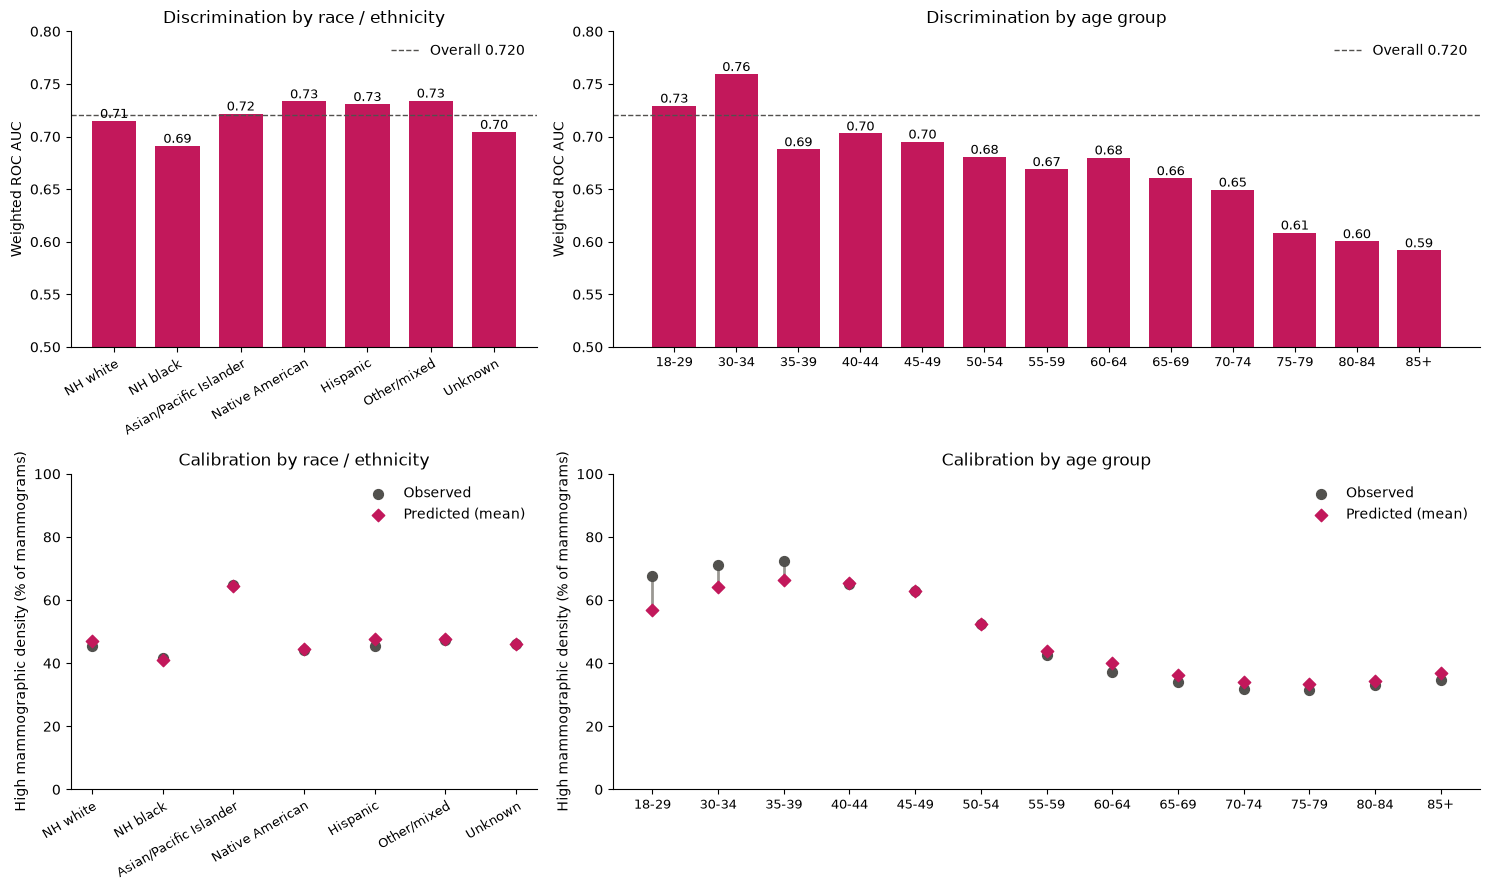

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9), gridspec_kw={"width_ratios": [7, 13]})
for col, var, title in ((0, "race_eth", "Race / ethnicity"), (1, "age_group_5_years", "Age group")):
    g = fairness[fairness["variable"] == var]
    labels = g["group"].str.replace("_", " ").str.replace("Non-Hispanic ", "NH ")
    ax = axes[0, col]
    ax.bar(labels, g["ROC_AUC"], color=PINK, width=0.7)
    ax.axhline(overall_auc, ls="--", c=INK_2, lw=1, label=f"Overall {overall_auc:.3f}")
    ax.bar_label(ax.containers[0], fmt="%.2f", fontsize=9)
    ax.set(ylim=(0.5, 0.8), ylabel="Weighted ROC AUC", title=f"Discrimination by {title.lower()}")
    ax.legend(frameon=False)
    ax = axes[1, col]
    x = np.arange(len(g))
    ax.scatter(x, g["observed"] * 100, color=INK_2, s=50, label="Observed", zorder=3)
    ax.scatter(x, g["predicted"] * 100, color=PINK, marker="D", s=40, label="Predicted (mean)", zorder=3)
    ax.vlines(x, g["observed"] * 100, g["predicted"] * 100, color=NEUTRAL, lw=2)
    ax.set_xticks(x, labels)
    ax.set(ylabel="High mammographic density (% of mammograms)", ylim=(0, 100), title=f"Calibration by {title.lower()}")
    ax.legend(frameon=False)
for ax in axes[:, 0]:
    ax.tick_params(axis="x", labelsize=9, rotation=30)
    plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")
for ax in axes[:, 1]:
    ax.tick_params(axis="x", labelsize=9)
sns.despine()
fig.tight_layout()
fig.savefig(FIG_DIR / "fairness_by_group.png", dpi=150)

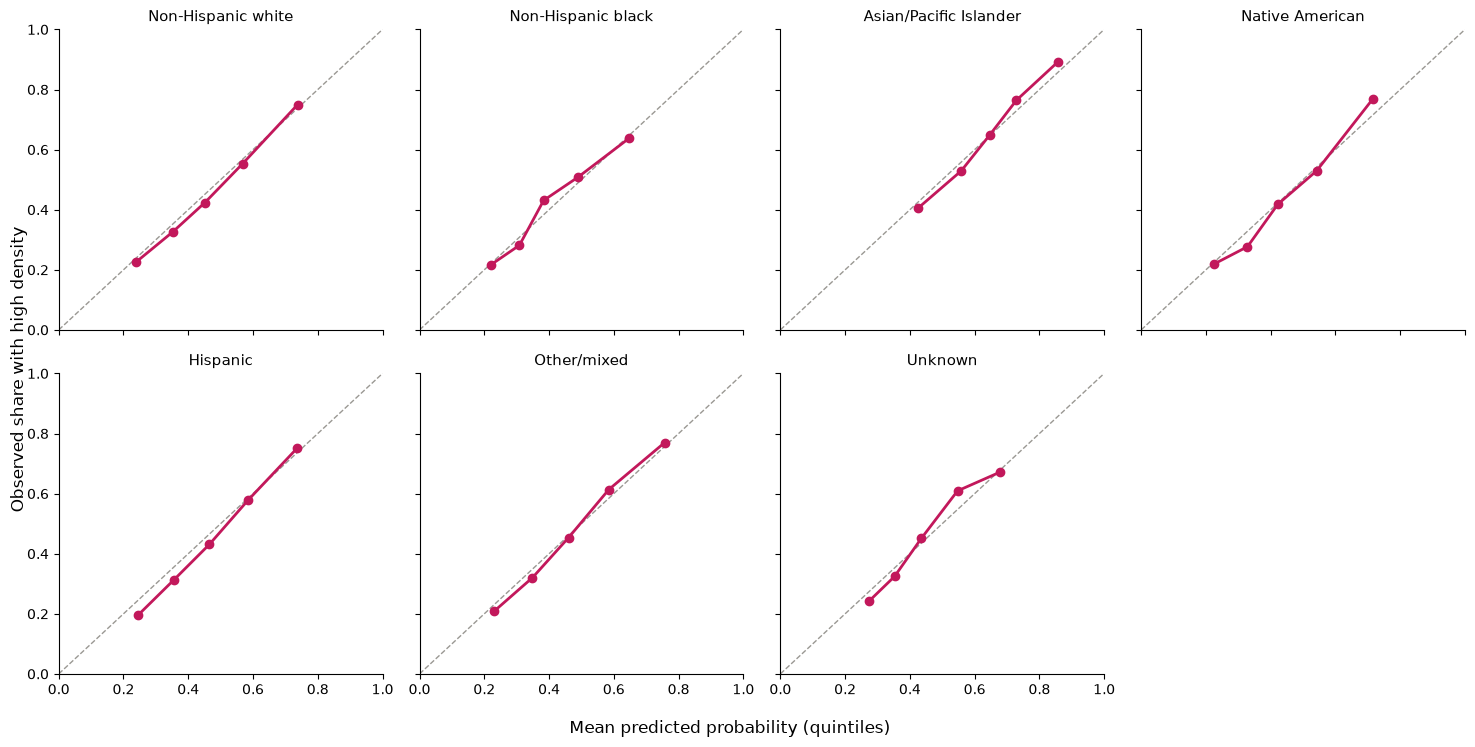

In [6]:
# calibration curves per race/ethnicity group (equal-weight quintiles of predicted probability)
def weighted_bins(y, p, w, n_bins=5):
    order = np.argsort(p)
    cum = np.cumsum(w[order]) / w.sum()
    b = np.minimum((cum * n_bins).astype(int), n_bins - 1)
    df = pd.DataFrame({"b": b, "p": p[order], "y": y[order], "w": w[order]})
    return df.groupby("b").apply(lambda d: pd.Series({"pred": np.average(d.p, weights=d.w),
                                                      "obs": np.average(d.y, weights=d.w)}))

race = group_of("race_eth")
groups = fairness.loc[fairness["variable"] == "race_eth", "group"]
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5), sharex=True, sharey=True)
for ax, g in zip(axes.flat, groups):
    m = (race == g).to_numpy()
    cal = weighted_bins(y_test.to_numpy()[m], p_test[m], w_test.to_numpy()[m])
    ax.plot([0, 1], [0, 1], ls="--", c=NEUTRAL, lw=1)
    ax.plot(cal["pred"], cal["obs"], marker="o", color=PINK, lw=2)
    ax.set_title(g.replace("_", " "), fontsize=11)
    ax.set(xlim=(0, 1), ylim=(0, 1))
axes.flat[-1].axis("off")
fig.supxlabel("Mean predicted probability (quintiles)")
fig.supylabel("Observed share with high density")
sns.despine()
fig.tight_layout()
fig.savefig(FIG_DIR / "calibration_by_race.png", dpi=150)

## 3. "Can you guess it?"

How confident is the model for an individual mammogram? The **uncertain zone** is a predicted probability between
0.35 and 0.65, close to a coin flip.

The **ceiling** below is the best any model could do with these 8 factors: for every exact combination of factors,
predict the share with high density actually observed in that combination (in-sample, so slightly optimistic).

In [7]:
in_zone = (p_test >= 0.35) & (p_test <= 0.65)
zone_share = w_test[in_zone].sum() / w_test.sum()
confident = ((p_test < 0.2) | (p_test > 0.8))
print(f"Uncertain zone 0.35–0.65: {zone_share:.1%} of test mammograms")
print(f"Confident (<0.2 or >0.8): {w_test[confident].sum() / w_test.sum():.1%}")

# best achievable with these factors: observed share per exact covariate pattern
VARS = MENO_HRT_FEATURES
pat = pd.DataFrame({v: lab(v).astype(str) for v in VARS})
pat["dense_w"] = known[TARGET].astype(int) * known["count"]
pat["w"] = known["count"]
patterns = pat.groupby(VARS)[["dense_w", "w"]].sum().reset_index()
patterns["observed"] = patterns["dense_w"] / patterns["w"]
patterns["predicted"] = predict(patterns)
long = pd.concat([patterns.assign(y=1, wt=patterns["dense_w"]), patterns.assign(y=0, wt=patterns["w"] - patterns["dense_w"])])
long = long[long["wt"] > 0]
ceiling_auc = roc_auc_score(long["y"], long["observed"], sample_weight=long["wt"])
print(f"Ceiling ROC AUC with these 8 factors (in-sample): {ceiling_auc:.3f} vs. model {overall_auc:.3f}")
print(f"{len(patterns):,} distinct factor combinations")

Uncertain zone 0.35–0.65: 52.7% of test mammograms
Confident (<0.2 or >0.8): 10.1%


Ceiling ROC AUC with these 8 factors (in-sample): 0.741 vs. model 0.720
92,836 distinct factor combinations


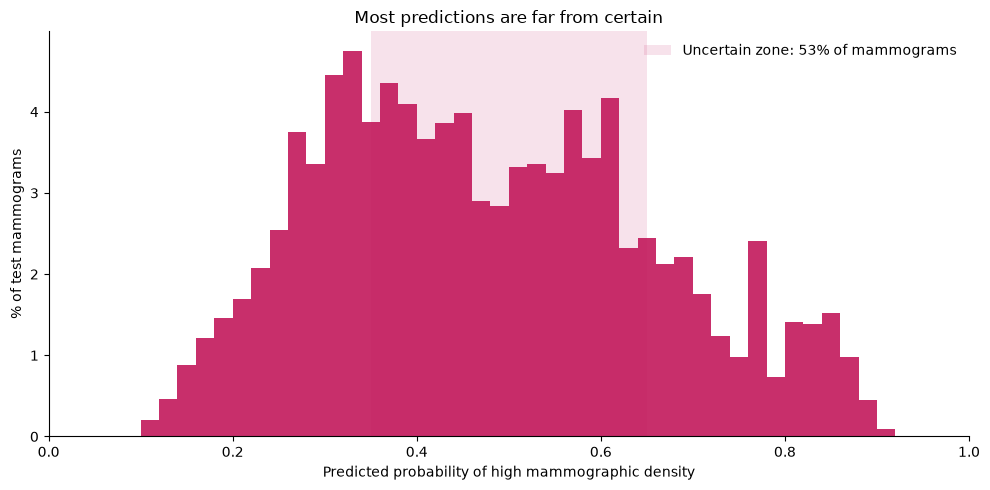

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
bins = np.linspace(0, 1, 51)
ax.axvspan(0.35, 0.65, color=PINK, alpha=0.12, lw=0, label=f"Uncertain zone: {zone_share:.0%} of mammograms")
ax.hist(p_test, bins=bins, weights=w_test / w_test.sum() * 100, color=PINK, alpha=0.9)
ax.set(xlabel="Predicted probability of high mammographic density", ylabel="% of test mammograms", xlim=(0, 1),
       title="Most predictions are far from certain")
ax.legend(frameon=False, loc="upper right")
sns.despine()
fig.tight_layout()
fig.savefig(FIG_DIR / "predicted_probability_distribution.png", dpi=150)

### Example profiles

Examples are drawn from real factor combinations with all 8 factors known and at least 30 mammograms.
- **Near-identical, very different:** pairs that differ in exactly **one** factor, with the largest gap in predicted probability (best pair per factor).
- **Very different, near-identical:** pairs that differ in **6 or more** of 8 factors but get almost the same prediction.

In [9]:
pretty = {"age_group_5_years": "Age", "race_eth": "Race/ethnicity", "first_degree_hx": "Family history",
          "age_menarche": "Age at first period", "age_first_birth": "Age at first birth",
          "bmi_group": "BMI", "biophx": "Prior biopsy", "meno_hrt": "Menopause/HRT"}
complete = patterns[(patterns[VARS] != "Unknown").all(axis=1) & (patterns["w"] >= 30)].reset_index(drop=True)


def show_pair(a, b, names=("Woman A", "Woman B")):
    t = pd.DataFrame({names[0]: complete.loc[a, VARS], names[1]: complete.loc[b, VARS]}).rename(index=pretty)
    t.loc["Predicted probability"] = [f"{complete.loc[i, 'predicted']:.0%}" for i in (a, b)]
    t.loc["Observed share (mammograms)"] = [f"{complete.loc[i, 'observed']:.0%} (n={complete.loc[i, 'w']:,})" for i in (a, b)]
    return t.style.apply(lambda r: ["font-weight:bold" if r.iloc[0] != r.iloc[1] else "" for _ in r], axis=1)


best_one_diff = []
for v in VARS:
    others = [o for o in VARS if o != v]
    grp = complete.groupby(others)["predicted"]
    gap = (grp.transform("max") - grp.transform("min"))
    i = gap.idxmax()
    key = complete.loc[i, others]
    members = complete[(complete[others] == key).all(axis=1)]
    best_one_diff.append({"differs_in": pretty[v], "gap": gap.max(),
                          "a": members["predicted"].idxmax(), "b": members["predicted"].idxmin()})
best_one_diff = pd.DataFrame(best_one_diff).sort_values("gap", ascending=False)
best_one_diff.assign(gap=lambda d: (d["gap"] * 100).round(1).astype(str) + " pp")[["differs_in", "gap"]]

,differs_in,gap
5,BMI,50.7 pp
0,Age,25.4 pp
7,Menopause/HRT,20.3 pp
4,Age at first birth,14.7 pp
1,Race/ethnicity,12.6 pp
6,Prior biopsy,8.8 pp
3,Age at first period,3.4 pp
2,Family history,1.3 pp


In [10]:
top = best_one_diff.iloc[0]
print(f"Near-identical profiles, differing only in {top['differs_in']}:")
show_pair(top["a"], top["b"])

Near-identical profiles, differing only in BMI:


,Woman A,Woman B
Age,45-49,45-49
Race/ethnicity,Non-Hispanic white,Non-Hispanic white
Family history,No,No
Age at first period,<12,<12
Age at first birth,Nulliparous,Nulliparous
BMI,10-24.99,35+
Prior biopsy,No,No
Menopause/HRT,Premenopausal,Premenopausal
Predicted probability,85%,35%
Observed share (mammograms),85% (n=736),28% (n=592)


In [11]:
# very different profiles, (almost) the same prediction: compare the 3,000 most common complete combinations
pool = complete.nlargest(3000, "w").reset_index()
codes = np.stack([pool[v].astype("category").cat.codes.to_numpy() for v in VARS], axis=1)
hamming = (codes[:, None, :] != codes[None, :, :]).sum(axis=2)
dp = np.abs(pool["predicted"].to_numpy()[:, None] - pool["predicted"].to_numpy()[None, :])
cand = np.argwhere((hamming >= 6) & (dp < 0.005) & np.triu(np.ones_like(dp, dtype=bool), 1))
order = np.lexsort((dp[cand[:, 0], cand[:, 1]], -hamming[cand[:, 0], cand[:, 1]]))
i, j = cand[order[0]]
print(f"{len(cand):,} pairs differ in ≥6 of 8 factors yet predictions are within 0.5 pp")
show_pair(pool.loc[i, "index"], pool.loc[j, "index"])

14,488 pairs differ in ≥6 of 8 factors yet predictions are within 0.5 pp


,Woman A,Woman B
Age,65-69,35-39
Race/ethnicity,Non-Hispanic white,Non-Hispanic black
Family history,Yes,No
Age at first period,12-13,<12
Age at first birth,25-29,<20
BMI,25-29.99,35+
Prior biopsy,Yes,No
Menopause/HRT,"Postmenopausal, no HRT",Premenopausal
Predicted probability,39%,39%
Observed share (mammograms),40% (n=282),39% (n=100)


## 4. What-if scenarios

Predicted probability (XGBoost) for typical profiles. Unless stated otherwise: non-Hispanic white, no family
history, first period at 12–13, first birth at 20–24, no prior biopsy. "Observed" is the actual share among mammograms
with exactly this combination (when it exists in the data). "BMI 30+" uses the 30–34.99 group.

In [12]:
DEFAULTS = {"race_eth": "Non-Hispanic white", "first_degree_hx": "No", "age_menarche": "12-13",
            "age_first_birth": "20-24", "biophx": "No"}
SCENARIOS = {
    "45, BMI <25, premenopausal": {"age_group_5_years": "45-49", "bmi_group": "10-24.99", "meno_hrt": "Premenopausal"},
    "45, BMI 30+, premenopausal": {"age_group_5_years": "45-49", "bmi_group": "30-34.99", "meno_hrt": "Premenopausal"},
    "60, BMI <25, postmenopausal on HRT": {"age_group_5_years": "60-64", "bmi_group": "10-24.99", "meno_hrt": "Postmenopausal, HRT"},
    "60, BMI 30+, postmenopausal on HRT": {"age_group_5_years": "60-64", "bmi_group": "30-34.99", "meno_hrt": "Postmenopausal, HRT"},
    "60, BMI 30+, postmenopausal, no HRT": {"age_group_5_years": "60-64", "bmi_group": "30-34.99", "meno_hrt": "Postmenopausal, no HRT"},
    "72, BMI 35+, postmenopausal, no HRT": {"age_group_5_years": "70-74", "bmi_group": "35+", "meno_hrt": "Postmenopausal, no HRT"},
    "42, BMI <25, premenopausal, Asian, no children": {"age_group_5_years": "40-44", "bmi_group": "10-24.99", "meno_hrt": "Premenopausal",
                                                       "race_eth": "Asian/Pacific Islander", "age_first_birth": "Nulliparous"},
    "42, BMI <25, premenopausal, mother/sister had breast cancer": {"age_group_5_years": "40-44", "bmi_group": "10-24.99",
                                                                   "meno_hrt": "Premenopausal", "first_degree_hx": "Yes"},
}
profiles = pd.DataFrame([{**DEFAULTS, **s} for s in SCENARIOS.values()], index=list(SCENARIOS))[VARS]
profiles["predicted"] = predict(profiles)
profiles = profiles.reset_index(names="profile").merge(patterns[VARS + ["observed", "w"]], on=VARS, how="left").set_index("profile")
profiles.to_csv(PROCESSED / "what_if_profiles.csv")
(profiles[["predicted", "observed", "w"]].rename(columns={"predicted": "Predicted", "observed": "Observed", "w": "Mammograms"})
 .style.format({"Predicted": "{:.0%}", "Observed": "{:.0%}", "Mammograms": "{:,.0f}"}, na_rep="–")
 .bar(subset=["Predicted"], color="#f3c6d8", vmin=0, vmax=1))

,Predicted,Observed,Mammograms
profile,,,
"45, BMI <25, premenopausal",81%,83%,"1,894"
"45, BMI 30+, premenopausal",52%,50%,"1,022"
"60, BMI <25, postmenopausal on HRT",58%,50%,131
"60, BMI 30+, postmenopausal on HRT",32%,26%,42
"60, BMI 30+, postmenopausal, no HRT",26%,20%,"1,872"
"72, BMI 35+, postmenopausal, no HRT",14%,11%,745
"42, BMI <25, premenopausal, Asian, no children",91%,94%,664
"42, BMI <25, premenopausal, mother/sister had breast cancer",82%,85%,201


## 5. Family history deep dive

Overall, family history barely moves density (raw 47.1% vs. 47.4%). Is that also true **within age groups and BMI
groups**, or does a real difference hide behind confounding (e.g. women with a family history being older or screened
differently)? Raw difference with 95% CI per stratum, plus the odds ratio adjusted for BMI and menopause/HRT within each age group.

In [13]:
fam = base[base["famhx"].notna()]


def famhx_by(stratum):
    rows = []
    for s, g in fam.groupby(stratum, sort=False):
        share = g.groupby("famhx").apply(lambda d: np.average(d["dense"], weights=d["w"]))
        n = g.groupby("famhx")["w"].sum()
        diff = share["Yes"] - share["No"]
        se = np.sqrt(share["Yes"] * (1 - share["Yes"]) / n["Yes"] + share["No"] * (1 - share["No"]) / n["No"])
        rows.append({"stratum": stratum, "group": s, "n_famhx_yes": n["Yes"], "n_famhx_no": n["No"],
                     "share_yes": share["Yes"], "share_no": share["No"], "diff_pp": diff * 100,
                     "diff_low": (diff - 1.96 * se) * 100, "diff_high": (diff + 1.96 * se) * 100})
    return pd.DataFrame(rows)


age_order = list(known["age_group_5_years_label"].cat.categories)
bmi_order = list(known["bmi_group_label"].cat.categories) + ["Unknown"]
by_age = famhx_by("age").set_index("group").loc[age_order].reset_index()
by_bmi = famhx_by("bmi").set_index("group").loc[bmi_order].reset_index()

adj_or = []
for a, g in fam.groupby("age"):
    agg = g.groupby(["famhx", "bmi", "meno_hrt", "dense"])["w"].sum().reset_index()
    fit = smf.glm("dense ~ C(famhx, Treatment('No')) + C(bmi) + C(meno_hrt)", agg, family=BINOMIAL, freq_weights=agg["w"]).fit()
    name = "C(famhx, Treatment('No'))[T.Yes]"
    lo, hi = np.exp(fit.conf_int().loc[name])
    adj_or.append({"group": a, "adj_OR": np.exp(fit.params[name]), "OR_low": lo, "OR_high": hi})
by_age = by_age.merge(pd.DataFrame(adj_or), on="group")
pd.concat([by_age, by_bmi]).to_csv(PROCESSED / "family_history_strata.csv", index=False)
fmt = {"n_famhx_yes": "{:,.0f}", "n_famhx_no": "{:,.0f}", "share_yes": "{:.1%}", "share_no": "{:.1%}",
       "diff_pp": "{:+.1f}", "diff_low": "{:+.1f}", "diff_high": "{:+.1f}", "adj_OR": "{:.2f}", "OR_low": "{:.2f}", "OR_high": "{:.2f}"}
display(by_age.style.format(fmt))
by_bmi.style.format(fmt)

,group,stratum,n_famhx_yes,n_famhx_no,share_yes,share_no,diff_pp,diff_low,diff_high,adj_OR,OR_low,OR_high
0,18-29,age,"1,824","5,996",74.5%,70.0%,+4.5,+2.2,+6.8,1.15,1.01,1.31
1,30-34,age,"7,824","24,787",72.0%,71.9%,+0.1,-1.1,+1.2,0.96,0.91,1.02
2,35-39,age,"25,783","100,051",70.1%,69.7%,+0.5,-0.2,+1.1,1.01,0.98,1.05
3,40-44,age,"75,025","548,383",68.0%,66.4%,+1.6,+1.2,+1.9,1.08,1.06,1.10
4,45-49,age,"106,806","656,137",65.2%,62.9%,+2.3,+2.0,+2.6,1.11,1.10,1.13
5,50-54,age,"137,335","730,768",54.8%,52.3%,+2.6,+2.3,+2.8,1.12,1.10,1.13
6,55-59,age,"152,653","714,511",45.5%,43.5%,+2.0,+1.7,+2.3,1.09,1.08,1.11
7,60-64,age,"146,623","635,846",40.6%,38.6%,+2.0,+1.7,+2.3,1.10,1.09,1.12
8,65-69,age,"126,869","527,933",37.1%,34.9%,+2.2,+1.9,+2.5,1.11,1.10,1.13
9,70-74,age,"95,632","376,105",34.7%,32.7%,+1.9,+1.6,+2.3,1.10,1.09,1.12


,group,stratum,n_famhx_yes,n_famhx_no,share_yes,share_no,diff_pp,diff_low,diff_high
0,10-24.99,bmi,"283,284","1,288,877",65.4%,65.9%,-0.5,-0.7,-0.3
1,25-29.99,bmi,"207,074","916,695",44.4%,44.7%,-0.3,-0.6,-0.1
2,30-34.99,bmi,"116,394","507,051",31.9%,32.0%,-0.1,-0.4,+0.2
3,35+,bmi,"89,072","390,550",21.9%,21.3%,+0.5,+0.2,+0.8
4,Unknown,bmi,"308,374","1,668,296",45.1%,45.3%,-0.2,-0.4,+0.0


In [14]:
# who reports a family history? (age mix explains why the raw overall gap is ~0 while within-age gaps are positive)
mix = fam.groupby(["famhx", "age"])["w"].sum().unstack(0)
mix = (mix / mix.sum() * 100).loc[age_order]
print("Mean age-group index (1=18-29 … 13=85+):",
      {k: round(np.average(np.arange(1, 14), weights=mix[k].to_numpy()), 2) for k in ("No", "Yes")})
print(f"Share aged 60+: No {mix.loc['60-64':, 'No'].sum():.1f}%  Yes {mix.loc['60-64':, 'Yes'].sum():.1f}%")

Mean age-group index (1=18-29 … 13=85+): {'No': np.float64(7.14), 'Yes': np.float64(7.55)}
Share aged 60+: No 41.7%  Yes 49.5%


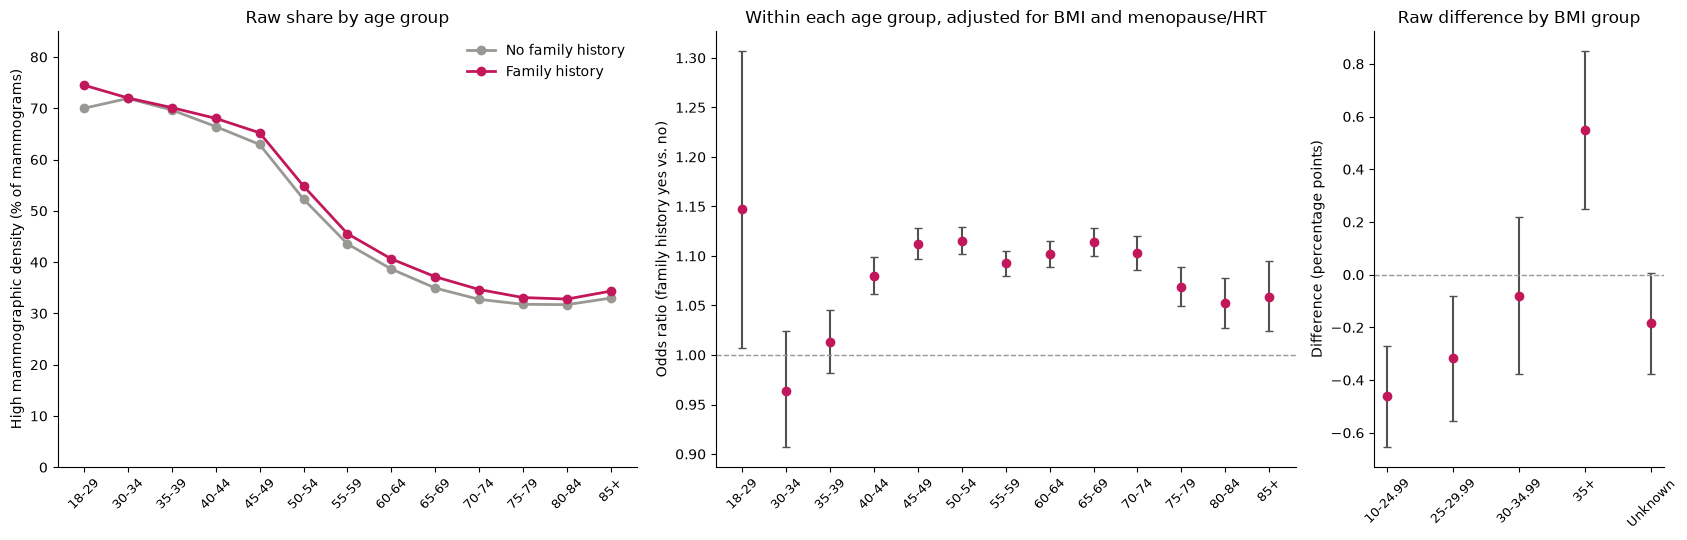

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), gridspec_kw={"width_ratios": [6, 6, 3]})
ax = axes[0]
ax.plot(age_order, by_age["share_no"] * 100, marker="o", color=NEUTRAL, lw=2, label="No family history")
ax.plot(age_order, by_age["share_yes"] * 100, marker="o", color=PINK, lw=2, label="Family history")
ax.set(ylabel="High mammographic density (% of mammograms)", ylim=(0, 85), title="Raw share by age group")
ax.legend(frameon=False)
ax = axes[1]
x = np.arange(len(age_order))
ax.errorbar(x, by_age["adj_OR"], yerr=[by_age["adj_OR"] - by_age["OR_low"], by_age["OR_high"] - by_age["adj_OR"]],
            fmt="o", color=PINK, ecolor=INK_2, capsize=3)
ax.axhline(1, ls="--", c=NEUTRAL, lw=1)
ax.set_xticks(x, age_order)
ax.set(ylabel="Odds ratio (family history yes vs. no)", title="Within each age group, adjusted for BMI and menopause/HRT")
ax = axes[2]
xb = np.arange(len(bmi_order))
ax.errorbar(xb, by_bmi["diff_pp"], yerr=[by_bmi["diff_pp"] - by_bmi["diff_low"], by_bmi["diff_high"] - by_bmi["diff_pp"]],
            fmt="o", color=PINK, ecolor=INK_2, capsize=3)
ax.axhline(0, ls="--", c=NEUTRAL, lw=1)
ax.set_xticks(xb, bmi_order)
ax.set(ylabel="Difference (percentage points)", title="Raw difference by BMI group")
for a in axes:
    a.tick_params(axis="x", rotation=45, labelsize=9)
sns.despine()
fig.tight_layout()
fig.savefig(FIG_DIR / "family_history_strata.png", dpi=150)

## Takeaways

1. **Adjusted vs. raw.** The Asian/Pacific Islander difference shrinks but stays large (raw OR 2.15 → adjusted 1.69;
   65% raw vs. 58% standardized). The *lower* raw density in non-Hispanic Black women (OR 0.80) **disappears**
   (adjusted 1.01): it is explained by BMI, age and menopause. HRT's association halves (1.63 → 1.28) but remains.
   Family history goes the other way: no raw difference (OR 0.99), but **a small effect appears after adjustment** (1.10).
2. **Fairness.** Discrimination is similar across race/ethnicity groups (AUC 0.69 NH Black to 0.73), and mean
   calibration is within ±2.4 pp for every group. Across age, AUC drops from 0.69–0.76 under 50 to 0.59 at 85+ (less
   variation left to explain within a narrow age band), and the model **under-predicts density in women under 40**
   by 6–11 pp. These are small groups (0.14–2.3% of test mammograms), down-weighted by the depth-2 trees. From age 55, it
   over-predicts slightly (1–3 pp).
3. **Can you guess it?** 52.7% of test mammograms get a prediction between 0.35 and 0.65; only 10.1% are below 0.2
   or above 0.8. Even a perfect lookup of the observed rate for every exact combination of the 8 factors only reaches
   AUC 0.741 (model 0.720). The factors set the odds; they cannot replace the mammogram. Changing a single factor
   can move the prediction by up to 51 pp (BMI: 85% vs. 35% for otherwise identical 45–49-year-olds), while 14,488
   pairs of profiles that differ in 6+ of 8 factors land within 0.5 pp of each other.
4. **What-if.** The predictions range from 91% (42, BMI <25, premenopausal, Asian, no children) to 14% (72, BMI 35+,
   postmenopausal, no HRT). For the 60-year-old profiles the model is 5–8 pp above the observed share, in line with the
   slight over-prediction from 55 on.
5. **Family history.** Within every age group from 40 on, women with a family history have 1–2.6 pp higher density
   (adjusted OR 1.05–1.12). The overall gap is ~0 because women reporting a family history are older (49.5% aged 60+
   vs. 41.7%), and mammographic density falls with age — a Simpson's-paradox-type masking. Within BMI groups (not age-
   adjusted) the raw gap stays within ±0.6 pp.
